In [1]:
!pip install pandas numpy matplotlib seaborn folium

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached markupsafe-3.0.4-cp315-cp315-win_amd64.whl.metadata (2.8 kB)
  Using cached charset_normalizer-3.5.2-cp315-cp315-win_amd64.whl.metadata (47 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.5 MB 3.1 MB/s eta 0:00:03
   ---- ----------------------------------- 1.0/9.5 MB 3.1 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/9.5 MB 2.4 MB/s eta 0:00:04
   ------- -------------------------------- 1.8/9.5 MB 2.2 MB/s eta 0:00:04
   ----------- ---------------------------- 2.6/9.5 MB 2.3 MB/s eta 0:00:03
   -------------- ------------------------- 3.4/9.5 MB 2.7 MB/s eta 0:

In [1]:
!pip install geopandas

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import json
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from pathlib import Path
import pandas as pd

PROJECT = Path.cwd().parent

MODULE2 = PROJECT / "data" / "processed" / "module2"

print("Module 2 folder:", MODULE2)
print("Folder exists:", MODULE2.exists())

route_df = pd.read_csv(
    MODULE2 / "all_cities_route_profile.csv"
)

hourly_df = pd.read_csv(
    MODULE2 / "all_cities_hourly_counts.csv"
)

route_hourly_df = pd.read_csv(
    MODULE2 / "all_cities_route_hourly_counts.csv"
)

period_df = pd.read_csv(
    MODULE2 / "all_cities_time_period_counts.csv"
)

print("All datasets loaded successfully!")

Module 2 folder: c:\Users\nagar\Downloads\routeranker-upload\data\processed\module2
Folder exists: True
All datasets loaded successfully!


In [4]:
datasets = {
    "Route Profile": route_df,
    "Hourly Counts": hourly_df,
    "Route Hourly Counts": route_hourly_df,
    "Time Period Counts": period_df
}

for name, df in datasets.items():

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("Shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nFirst 5 records:")
    display(df.head())

    print("\nLast 5 records:")
    display(df.tail())

    print("\nDescriptive Statistics:")
    display(df.describe(include="all").T)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Records:")
    print(df.duplicated().sum())


Route Profile
Shape: (9679, 10)

Columns:
['route_long_name', 'route_short_name', 'agency_id', 'route_type', 'route_id', 'trip_count', 'service_count', 'distinct_stop_count', 'average_stops_per_trip', 'city']

Data Types:
route_long_name            object
route_short_name           object
agency_id                  object
route_type                  int64
route_id                   object
trip_count                float64
service_count             float64
distinct_stop_count       float64
average_stops_per_trip    float64
city                       object
dtype: object

First 5 records:


,route_long_name,route_short_name,agency_id,route_type,route_id,trip_count,service_count,distinct_stop_count,average_stops_per_trip,city
0,2nd Stage 9th Block Nagarabhavi ⇔ Shivajinagar...,244-C VSD,1,3,3447,2.0,1.0,41.0,21.500000,Bangalore
1,5th Block HBR Layout ⇔ Kalyananagara Bus Stand,KLN-HBR,1,3,7041,2.0,1.0,7.0,4.500000,Bangalore
2,5th Block HBR Layout ⇔ Kempegowda Bus Station,296,1,3,2712,3.0,1.0,44.0,22.333333,Bangalore
3,5th Block HBR Layout ⇔ Kempegowda Bus Station,296-B,1,3,4821,4.0,1.0,44.0,22.500000,Bangalore
4,5th Block HBR Layout ⇔ Shivajinagara Bus Station,296-D,1,3,2809,3.0,1.0,38.0,19.000000,Bangalore



Last 5 records:


,route_long_name,route_short_name,agency_id,route_type,route_id,trip_count,service_count,distinct_stop_count,average_stops_per_trip,city
9674,Mariaai Gate Navin St Stand ⇆ Katraj,RATRANI 1,PMPML,3,RATRANI 1,8.0,1.0,44.0,26.500000,Pune
9675,Pune Station Moledina Stand ⇆ Katraj,RATRANI 2,PMPML,3,RATRANI 2,9.0,1.0,43.0,26.444444,Pune
9676,Hadapsar Gadital ⇆ Swargate,RATRANI 3,PMPML,3,RATRANI 3,9.0,1.0,30.0,18.000000,Pune
9677,Pune Station St. Helena'S Stand ⇆ Hadapsar Gad...,RATRANI 4,PMPML,3,RATRANI 4,7.0,1.0,30.0,17.142857,Pune
9678,Nda 10 No. Gate ⇆ Pune Station Moledina Stand,RATRANI 7,PMPML,3,RATRANI 7,6.0,1.0,95.0,50.000000,Pune



Descriptive Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
route_long_name,9679,8369,Kempegowda Bus Station ⇔ Kempegowda Bus Station,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
route_short_name,5684,5197,3,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
agency_id,9679,9,1,4434,NaN,NaN,NaN,NaN,NaN,NaN,NaN
route_type,9679.0,NaN,NaN,NaN,3.0,0.0,3.0,3.0,3.0,3.0,3.0
route_id,9679,8142,152,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trip_count,9338.0,NaN,NaN,NaN,31.103341,73.207705,1.0,2.0,8.0,28.0,2087.0
service_count,9338.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
distinct_stop_count,9338.0,NaN,NaN,NaN,48.123581,33.793734,1.0,26.0,43.0,63.0,795.0
average_stops_per_trip,9338.0,NaN,NaN,NaN,32.432758,17.682865,1.0,19.25,32.0,44.666667,169.0
city,9679,5,Bangalore,4434,NaN,NaN,NaN,NaN,NaN,NaN,NaN


... (15 outputs left out)

,city,time_period,departure_count
15,Mumbai,Night,412237
16,Pune,Afternoon,147118
17,Pune,Evening,12100
18,Pune,Morning,266126
19,Pune,Night,3958



Descriptive Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
city,20,5,Bangalore,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time_period,20,4,Afternoon,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departure_count,20.0,NaN,NaN,NaN,451695.65,327402.706812,3958.0,263258.0,364267.0,649798.75,1156642.0



Missing Values:
city               0
time_period        0
departure_count    0
dtype: int64

Duplicate Records:
0


In [5]:
print(route_df.columns.tolist())

['route_long_name', 'route_short_name', 'agency_id', 'route_type', 'route_id', 'trip_count', 'service_count', 'distinct_stop_count', 'average_stops_per_trip', 'city']


FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\nagar\\Downloads\\routeranker-upload\\visualizations\\distributions\\trip_count_distribution.png'

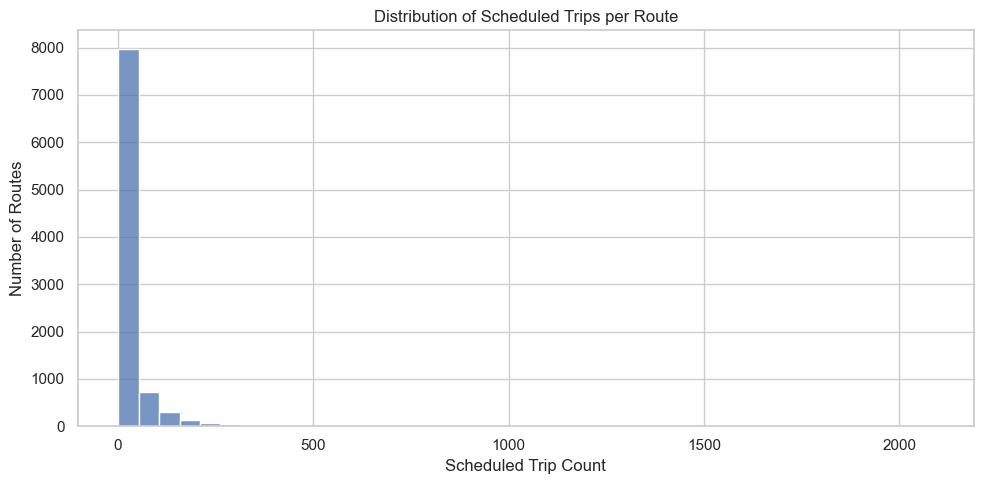

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=route_df,
    x="trip_count",
    bins=40
)

plt.title("Distribution of Scheduled Trips per Route")
plt.xlabel("Scheduled Trip Count")
plt.ylabel("Number of Routes")

plt.tight_layout()

plt.savefig(
    PROJECT / "visualizations" / "distributions" /
    "trip_count_distribution.png",
    dpi=300
)

plt.show()

In [22]:
from pathlib import Path

visualization_folder = PROJECT / "visualizations"

folders = [
    "distributions",
    "hourly_patterns",
    "route_comparisons",
    "geography",
    "correlations"
]

for folder in folders:
    (visualization_folder / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("All visualization folders created successfully!")

print(list(visualization_folder.iterdir()))

All visualization folders created successfully!
[WindowsPath('c:/Users/nagar/Downloads/routeranker-upload/visualizations/correlations'), WindowsPath('c:/Users/nagar/Downloads/routeranker-upload/visualizations/distributions'), WindowsPath('c:/Users/nagar/Downloads/routeranker-upload/visualizations/geography'), WindowsPath('c:/Users/nagar/Downloads/routeranker-upload/visualizations/hourly_patterns'), WindowsPath('c:/Users/nagar/Downloads/routeranker-upload/visualizations/route_comparisons')]


In [23]:
plt.savefig(
    PROJECT / "visualizations" / "distributions" /
    "trip_count_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Trip count distribution chart saved successfully!")

<Figure size 640x480 with 0 Axes>

Trip count distribution chart saved successfully!


In [24]:
chart_path = (
    PROJECT / "visualizations" /
    "distributions" /
    "trip_count_distribution.png"
)

print("Image exists:", chart_path.exists())
print("Image location:", chart_path)

Image exists: True
Image location: c:\Users\nagar\Downloads\routeranker-upload\visualizations\distributions\trip_count_distribution.png


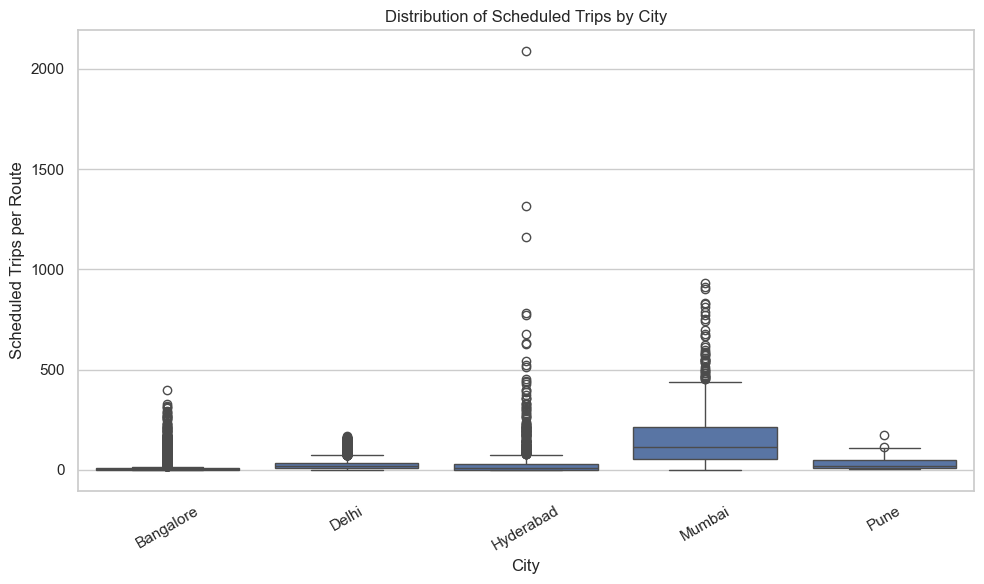

City-wise trip distribution chart saved successfully!


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=route_df,
    x="city",
    y="trip_count"
)

plt.title("Distribution of Scheduled Trips by City")
plt.xlabel("City")
plt.ylabel("Scheduled Trips per Route")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    PROJECT / "visualizations" / "distributions" /
    "trip_distribution_by_city.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("City-wise trip distribution chart saved successfully!")

In [26]:
chart_path = (
    PROJECT / "visualizations" / "distributions" /
    "trip_distribution_by_city.png"
)

print("Chart exists:", chart_path.exists())
print("Chart path:", chart_path)

Chart exists: True
Chart path: c:\Users\nagar\Downloads\routeranker-upload\visualizations\distributions\trip_distribution_by_city.png


In [27]:
hourly_df = pd.read_csv(
    MODULE2 / "all_cities_hourly_counts.csv"
)

print("Dataset shape:", hourly_df.shape)
print("\nAvailable columns:")
print(hourly_df.columns.tolist())

print("\nFirst 10 rows:")
display(hourly_df.head(10))

Dataset shape: (120, 3)

Available columns:
['city', 'hour', 'trip_count']

First 10 rows:


,city,hour,trip_count
0,Bangalore,0,43
1,Bangalore,1,44
2,Bangalore,2,31
3,Bangalore,3,72
4,Bangalore,4,583
5,Bangalore,5,1998
6,Bangalore,6,3448
7,Bangalore,7,4115
8,Bangalore,8,4504
9,Bangalore,9,3379


In [28]:
print("Cities:")
print(hourly_df["city"].unique())

print("\nHourly data:")
print(hourly_df.groupby("city").size())

Cities:
['Bangalore' 'Delhi' 'Hyderabad' 'Mumbai' 'Pune']

Hourly data:
city
Bangalore    24
Delhi        24
Hyderabad    24
Mumbai       24
Pune         24
dtype: int64


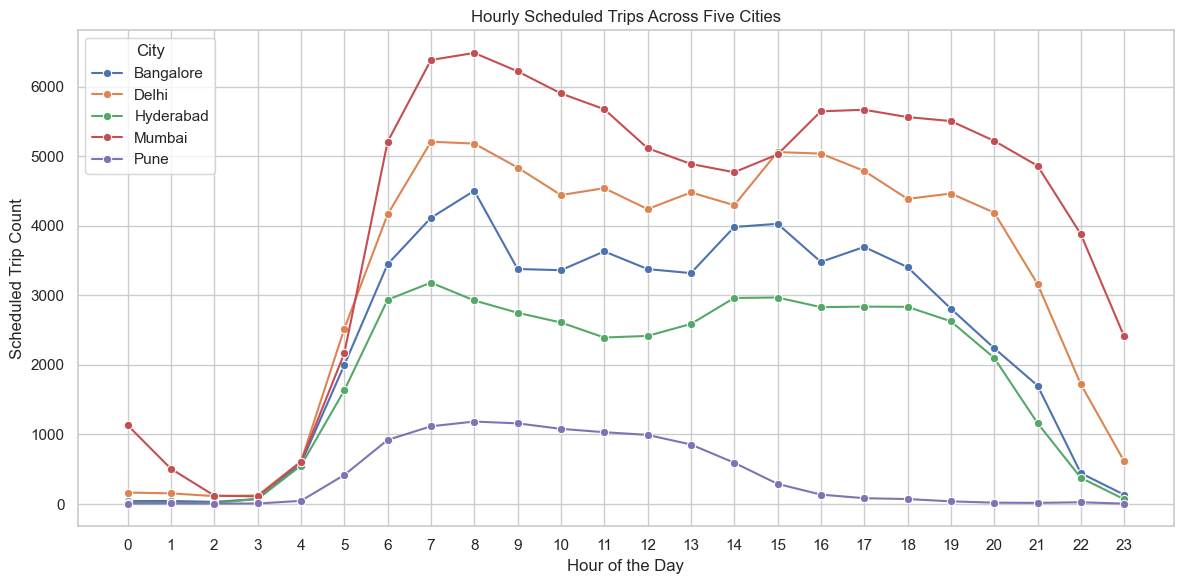

Hourly comparison chart saved successfully!


In [29]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_df,
    x="hour",
    y="trip_count",
    hue="city",
    marker="o"
)

plt.title("Hourly Scheduled Trips Across Five Cities")
plt.xlabel("Hour of the Day")
plt.ylabel("Scheduled Trip Count")
plt.xticks(range(0, 24))
plt.grid(True)
plt.legend(title="City")
plt.tight_layout()

plt.savefig(
    PROJECT / "visualizations" / "hourly_patterns" /
    "hourly_trips_all_cities.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Hourly comparison chart saved successfully!")

In [30]:
time_period_df = pd.read_csv(
    MODULE2 / "all_cities_time_period_counts.csv"
)

print("Dataset shape:", time_period_df.shape)
print("\nColumns:")
print(time_period_df.columns.tolist())

display(time_period_df.head(10))

Dataset shape: (20, 3)

Columns:
['city', 'time_period', 'departure_count']


,city,time_period,departure_count
0,Bangalore,Afternoon,446664
1,Bangalore,Evening,350645
2,Bangalore,Morning,641548
3,Bangalore,Night,101829
4,Delhi,Afternoon,947975
5,Delhi,Evening,793586
6,Delhi,Morning,1156642
7,Delhi,Night,377889
8,Hyderabad,Afternoon,286796
9,Hyderabad,Evening,254654


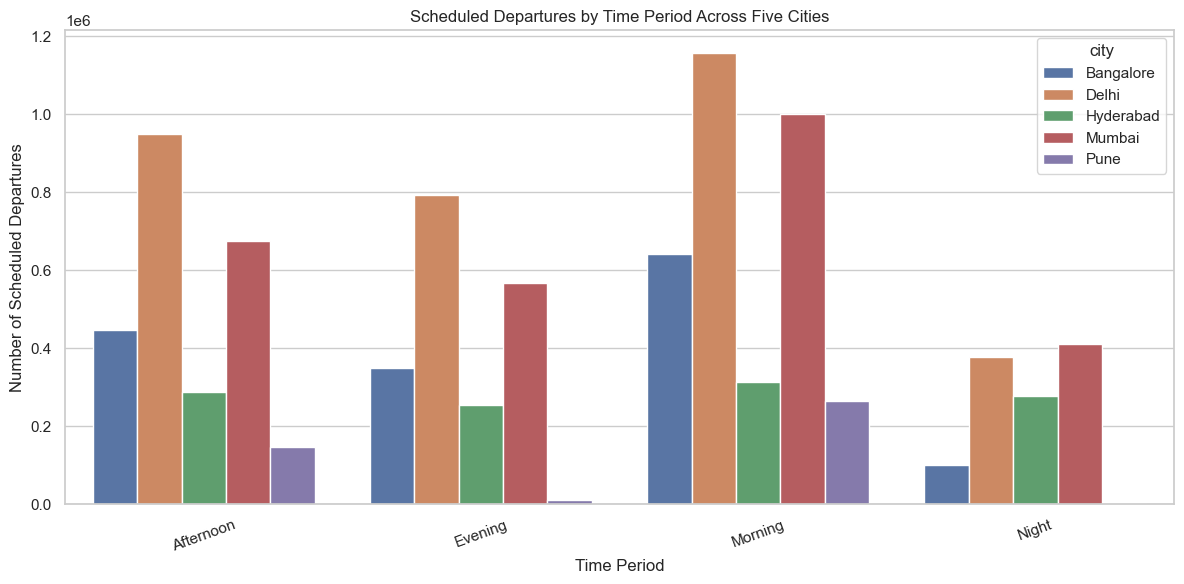

Time-period comparison chart saved successfully!


In [32]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=time_period_df,
    x="time_period",
    y="departure_count",
    hue="city"
)

plt.title("Scheduled Departures by Time Period Across Five Cities")
plt.xlabel("Time Period")
plt.ylabel("Number of Scheduled Departures")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    PROJECT / "visualizations" / "hourly_patterns" /
    "time_period_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Time-period comparison chart saved successfully!")

In [33]:
chart_path = (
    PROJECT / "visualizations" / "hourly_patterns" /
    "time_period_comparison.png"
)

print("Chart exists:", chart_path.exists())

Chart exists: True


In [34]:
route_df = pd.read_csv(
    MODULE2 / "all_cities_route_profile.csv"
)

print("Dataset shape:", route_df.shape)
print("\nAvailable columns:")
print(route_df.columns.tolist())

display(route_df.head())

Dataset shape: (9679, 10)

Available columns:
['route_long_name', 'route_short_name', 'agency_id', 'route_type', 'route_id', 'trip_count', 'service_count', 'distinct_stop_count', 'average_stops_per_trip', 'city']


,route_long_name,route_short_name,agency_id,route_type,route_id,trip_count,service_count,distinct_stop_count,average_stops_per_trip,city
0,2nd Stage 9th Block Nagarabhavi ⇔ Shivajinagar...,244-C VSD,1,3,3447,2.0,1.0,41.0,21.500000,Bangalore
1,5th Block HBR Layout ⇔ Kalyananagara Bus Stand,KLN-HBR,1,3,7041,2.0,1.0,7.0,4.500000,Bangalore
2,5th Block HBR Layout ⇔ Kempegowda Bus Station,296,1,3,2712,3.0,1.0,44.0,22.333333,Bangalore
3,5th Block HBR Layout ⇔ Kempegowda Bus Station,296-B,1,3,4821,4.0,1.0,44.0,22.500000,Bangalore
4,5th Block HBR Layout ⇔ Shivajinagara Bus Station,296-D,1,3,2809,3.0,1.0,38.0,19.000000,Bangalore


In [35]:
city_route_summary = (
    route_df.groupby("city")["trip_count"]
    .agg(["count", "sum", "mean", "median", "max"])
    .reset_index()
)

city_route_summary.columns = [
    "city",
    "route_count",
    "total_scheduled_trips",
    "average_trips_per_route",
    "median_trips_per_route",
    "maximum_trips_on_a_route"
]

display(city_route_summary.round(2))

,city,route_count,total_scheduled_trips,average_trips_per_route,median_trips_per_route,maximum_trips_on_a_route
0,Bangalore,4416,57836.0,13.10,3.0,398.0
1,Delhi,2964,78507.0,26.49,18.0,170.0
2,Hyderabad,1031,44892.0,43.54,8.0,2087.0
3,Mumbai,612,99080.0,161.90,116.0,930.0
4,Pune,315,10128.0,32.15,22.0,175.0


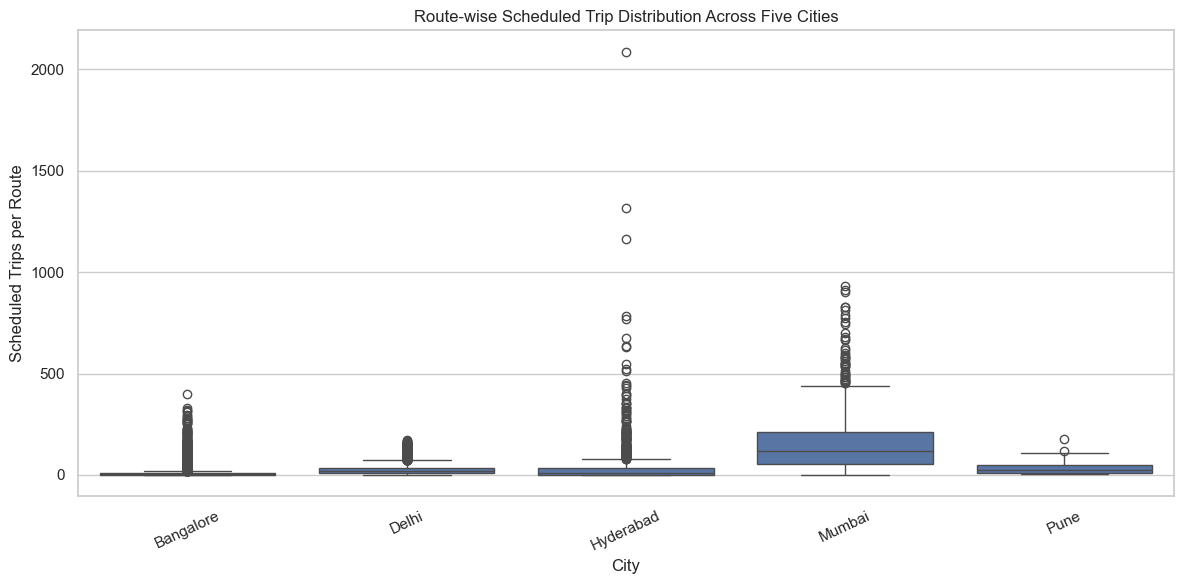

Route comparison chart saved successfully!


In [36]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=route_df,
    x="city",
    y="trip_count"
)

plt.title("Route-wise Scheduled Trip Distribution Across Five Cities")
plt.xlabel("City")
plt.ylabel("Scheduled Trips per Route")
plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig(
    PROJECT / "visualizations" / "route_comparisons" /
    "route_trip_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Route comparison chart saved successfully!")

In [37]:
city_route_summary.to_csv(
    PROJECT / "data" / "processed" / "module3" /
    "city_route_summary.csv",
    index=False
)

print("City-wise route summary CSV saved successfully!")

City-wise route summary CSV saved successfully!


In [38]:
headway_df = pd.read_csv(
    MODULE2 / "all_cities_headway_features.csv"
)

print("Dataset shape:", headway_df.shape)
print("\nAvailable columns:")
print(headway_df.columns.tolist())

display(headway_df.head())

Dataset shape: (266597, 15)

Available columns:
['trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence', 'stop_headsign', 'route_id', 'service_id', 'direction_id', 'hour', 'minute', 'departure_minutes', 'headway_minutes', 'city', 'timepoint']


,trip_id,arrival_time,departure_time,stop_id,stop_sequence,stop_headsign,route_id,service_id,direction_id,hour,minute,departure_minutes,headway_minutes,city,timepoint
0,1094,05:10:00,05:10:00,20921,1,Chandapura,1000,1,0.0,5,10,310,NaN,Bangalore,NaN
1,1095,05:20:00,05:20:00,20921,1,Chandapura,1000,1,0.0,5,20,320,10.0,Bangalore,NaN
2,1096,05:40:00,05:40:00,20921,1,Chandapura,1000,1,0.0,5,40,340,20.0,Bangalore,NaN
3,1097,06:05:00,06:05:00,20921,1,Chandapura,1000,1,0.0,6,5,365,25.0,Bangalore,NaN
4,1098,06:10:00,06:10:00,20921,1,Chandapura,1000,1,0.0,6,10,370,5.0,Bangalore,NaN


In [39]:
display(headway_df.describe().round(2))

,stop_sequence,direction_id,hour,minute,departure_minutes,headway_minutes,timepoint
count,266597.00,191054.00,266597.00,266597.00,266597.00,254024.00,140693.00
mean,0.72,0.49,13.34,28.18,828.78,25.35,0.76
std,0.45,0.50,5.17,17.37,310.11,59.22,0.43
min,0.00,0.00,0.00,0.00,1.00,1.00,0.00
25%,0.00,0.00,9.00,14.00,570.00,5.00,1.00
50%,1.00,0.00,13.00,29.00,822.00,11.00,1.00
75%,1.00,1.00,17.00,44.00,1072.00,24.00,1.00
max,1.00,1.00,86.00,59.00,5165.00,4315.00,1.00


In [40]:
headway_summary = (
    headway_df.groupby("city")["headway_minutes"]
    .agg(["count", "mean", "median", "min", "max"])
    .reset_index()
)

display(headway_summary.round(2))

,city,count,mean,median,min,max
0,Bangalore,45998,38.07,15.0,1.0,1050.0
1,Delhi,72675,25.35,16.0,1.0,1208.0
2,Hyderabad,29718,48.94,16.0,1.0,4315.0
3,Mumbai,96750,11.60,7.0,1.0,1067.0
4,Pune,8883,30.40,20.0,1.0,1225.0


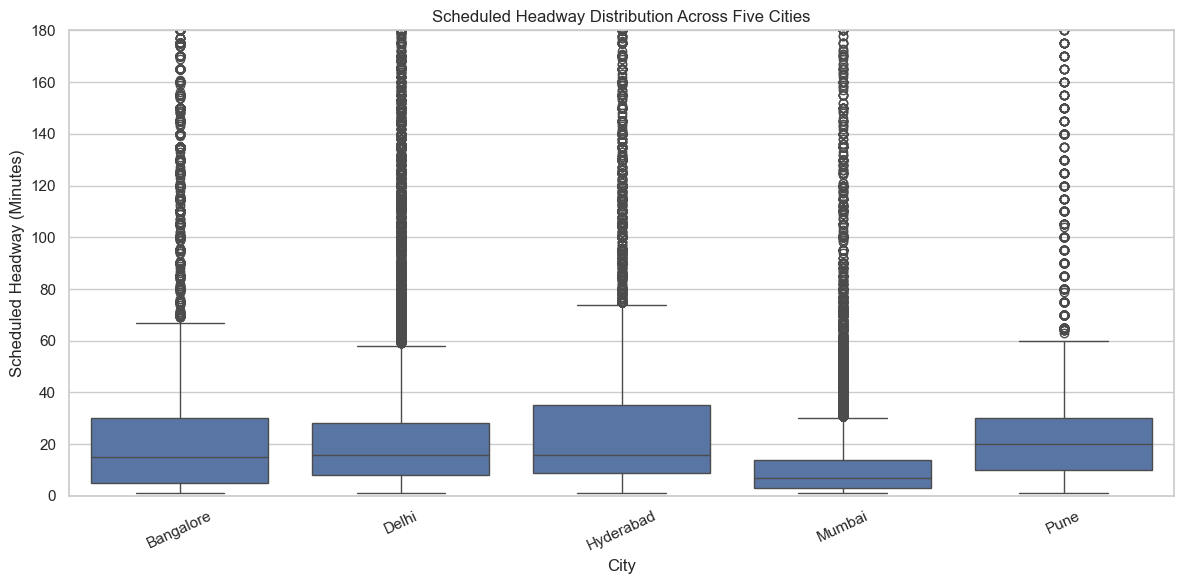

Headway comparison chart saved successfully!


In [41]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=headway_df,
    x="city",
    y="headway_minutes"
)

plt.title("Scheduled Headway Distribution Across Five Cities")
plt.xlabel("City")
plt.ylabel("Scheduled Headway (Minutes)")
plt.xticks(rotation=25)
plt.ylim(0, 180)
plt.tight_layout()

plt.savefig(
    PROJECT / "visualizations" / "route_comparisons" /
    "headway_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Headway comparison chart saved successfully!")

In [42]:
route_hourly_df = pd.read_csv(
    MODULE2 / "all_cities_route_hourly_counts.csv"
)

print("Dataset shape:", route_hourly_df.shape)
print("\nAvailable columns:")
print(route_hourly_df.columns.tolist())

display(route_hourly_df.head())

Dataset shape: (73039, 4)

Available columns:
['city', 'route_id', 'hour', 'trip_count']


,city,route_id,hour,trip_count
0,Bangalore,991,5,6
1,Bangalore,991,6,10
2,Bangalore,991,7,14
3,Bangalore,991,8,13
4,Bangalore,991,9,12


In [43]:
route_hourly_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73039 entries, 0 to 73038
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   city        73039 non-null  object
 1   route_id    73039 non-null  object
 2   hour        73039 non-null  int64 
 3   trip_count  73039 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 2.2+ MB


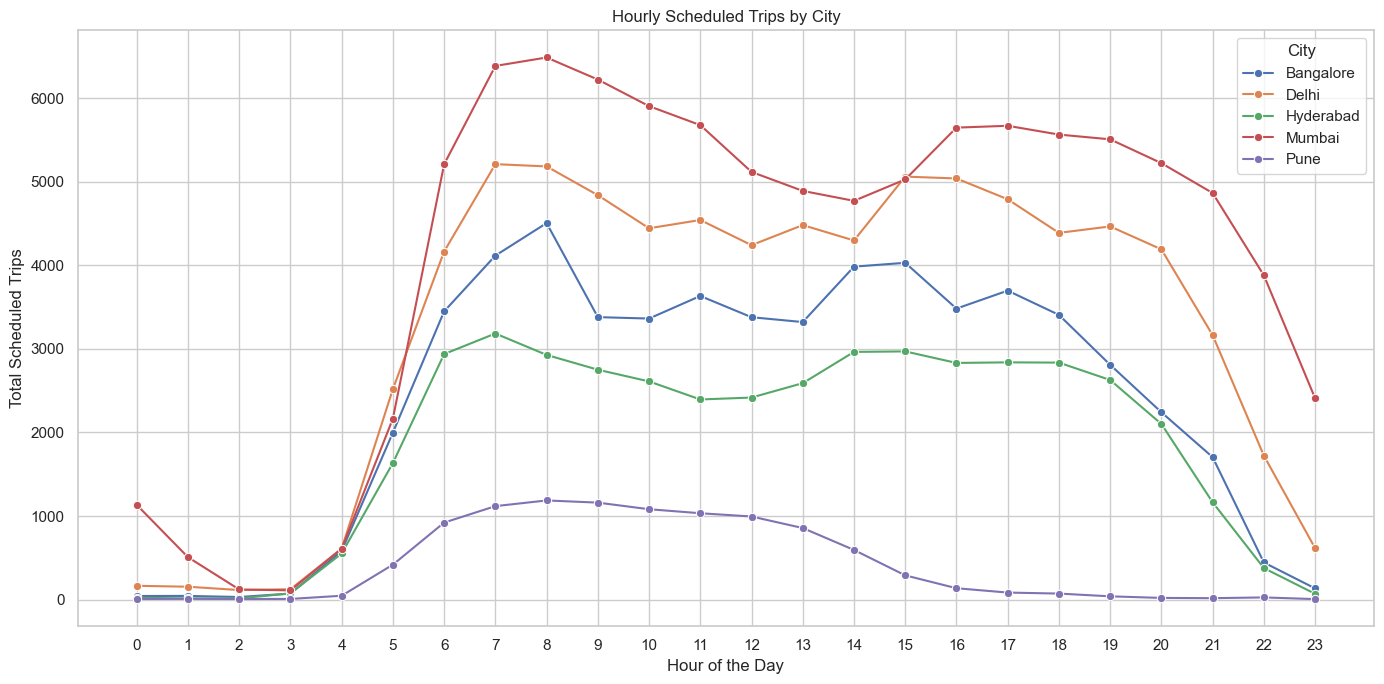

Route-wise hourly comparison chart saved successfully!


In [44]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=route_hourly_df,
    x="hour",
    y="trip_count",
    hue="city",
    estimator="sum",
    errorbar=None,
    marker="o"
)

plt.title("Hourly Scheduled Trips by City")
plt.xlabel("Hour of the Day")
plt.ylabel("Total Scheduled Trips")
plt.xticks(range(0, 24))
plt.grid(True)
plt.legend(title="City")
plt.tight_layout()

plt.savefig(
    PROJECT / "visualizations" / "hourly_patterns" /
    "route_wise_hourly_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Route-wise hourly comparison chart saved successfully!")

In [45]:
route_hourly_summary = (
    route_hourly_df.groupby(["city", "hour"])["trip_count"]
    .sum()
    .reset_index()
)

route_hourly_summary.to_csv(
    PROJECT / "data" / "processed" / "module3" /
    "route_hourly_summary.csv",
    index=False
)

print("Route hourly summary CSV saved successfully!")

Route hourly summary CSV saved successfully!


In [46]:
top_routes = (
    route_df.sort_values(
        ["city", "trip_count"],
        ascending=[True, False]
    )
    .groupby("city")
    .head(10)
    .copy()
)

display(top_routes[
    ["city", "route_id", "route_long_name", "trip_count"]
])

,city,route_id,route_long_name,trip_count
345,Bangalore,1576,Banashankari Bus Station ⇔ Kengeri Bus Station,398.0
4413,Bangalore,1086,Yeshawanthapura Bus Station ⇔ Kengeri Bus Station,328.0
2809,Bangalore,1100,Kengeri Bus Station ⇔ Electronic City 378,318.0
4396,Bangalore,1659,Yeshawanthapura Bus Station ⇔ Banashankari Bus...,316.0
494,Bangalore,1133,Bidadi ⇔ Kempegowda Bus Station,310.0
148,Bangalore,1508,Attibele Bus Stand ⇔ Banashankari Bus Station,295.0
4431,Bangalore,3451,Yeshawanthapura Railway Station ⇔ Kempegowda B...,290.0
3527,Bangalore,1621,Peenya 2nd Stage ⇔ Kempegowda Bus Station,283.0
2761,Bangalore,1101,Kempegowda International Airport ⇔ Kempegowda ...,279.0
4375,Bangalore,1324,Yelahanka Old Town ⇔ Shivajinagara Bus Station,270.0


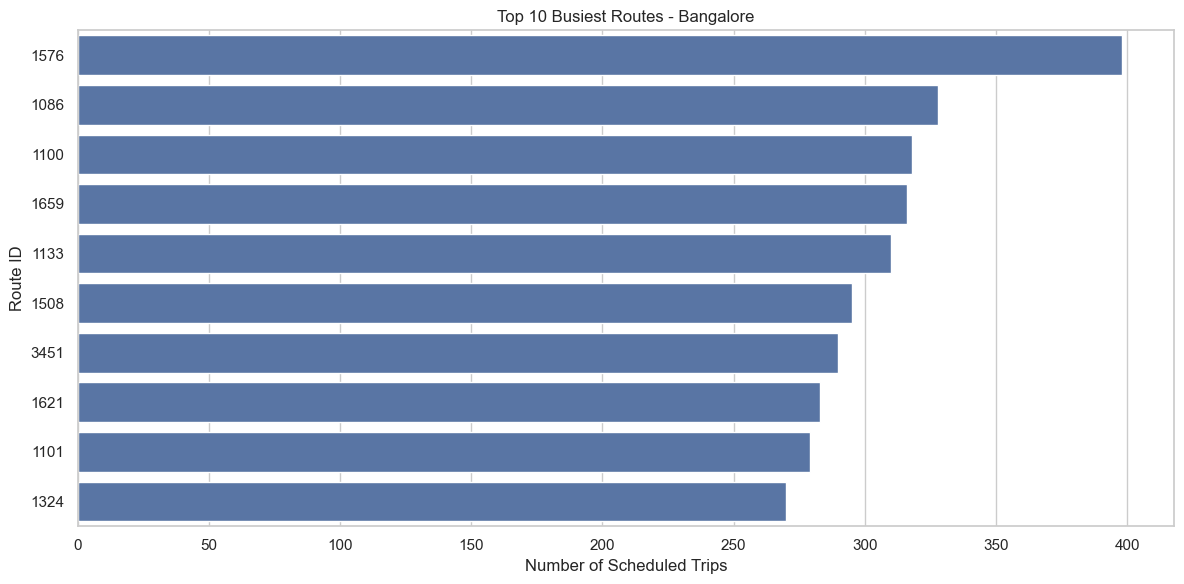

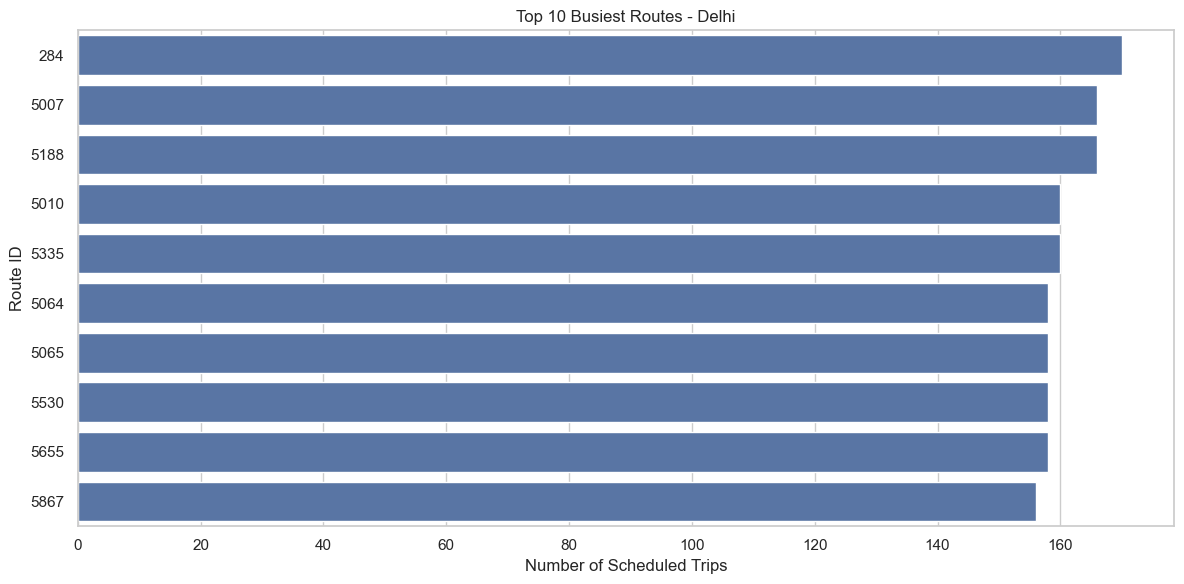

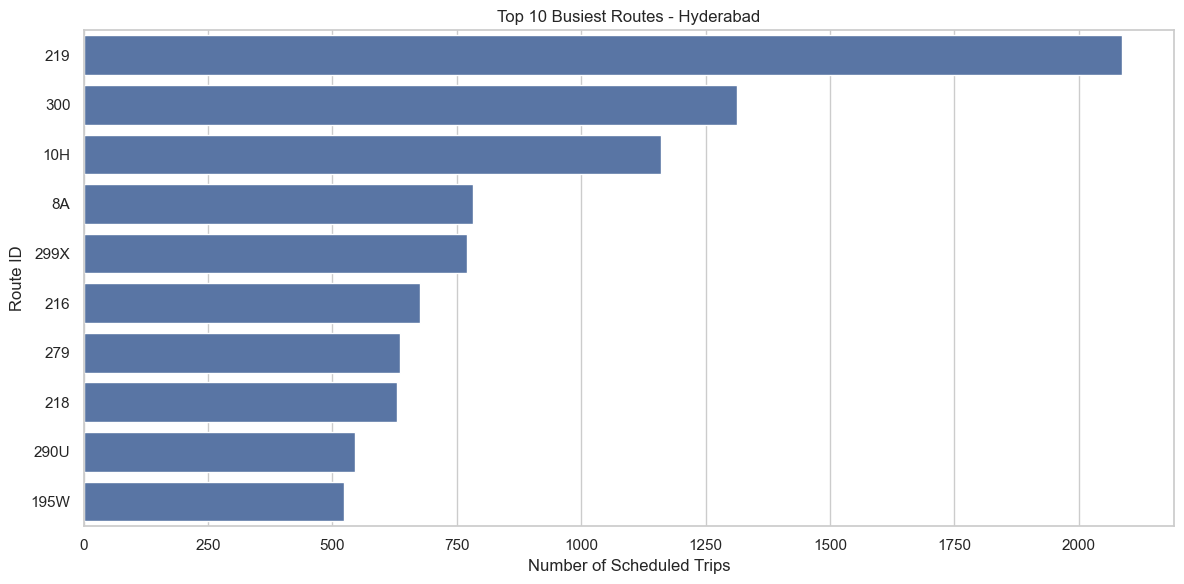

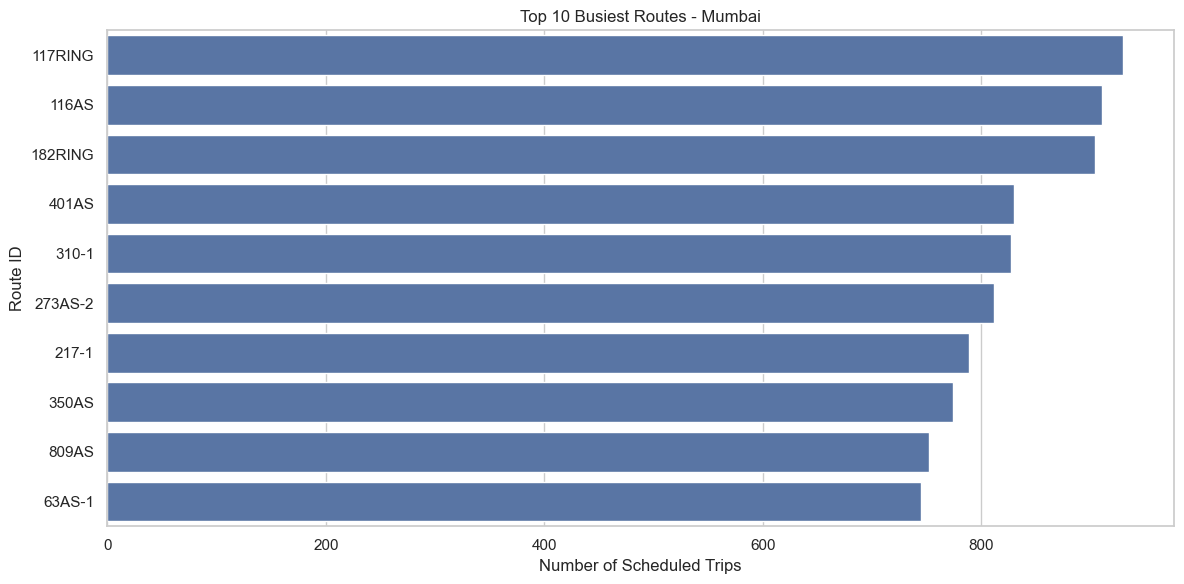

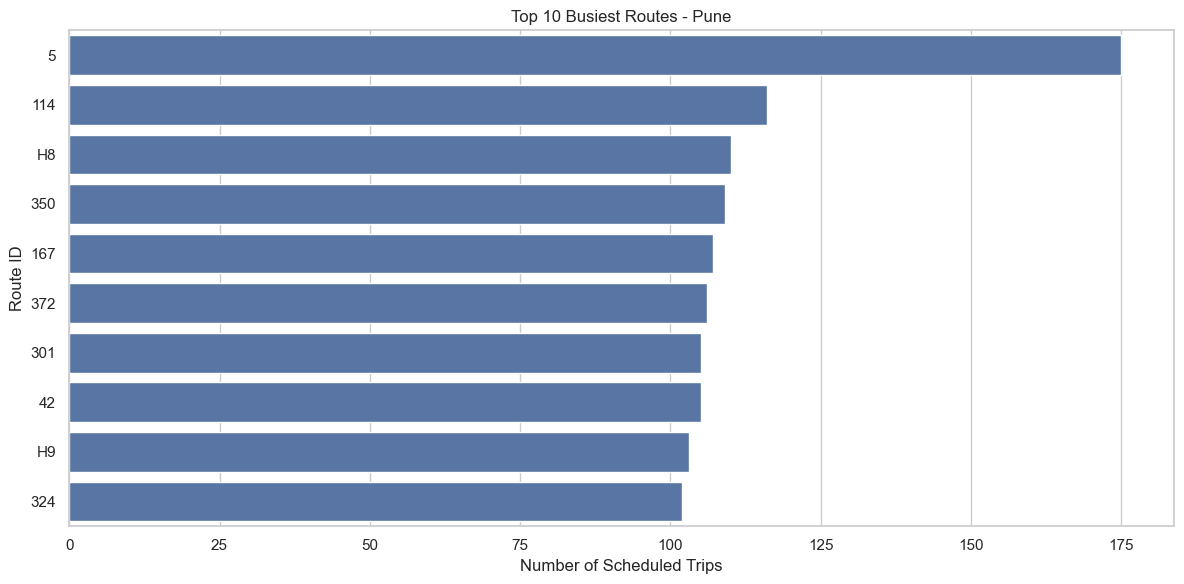

Top 10 route charts saved successfully!


In [47]:
cities = top_routes["city"].unique()

for city in cities:
    city_data = top_routes[top_routes["city"] == city]

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=city_data,
        x="trip_count",
        y="route_id"
    )

    plt.title(f"Top 10 Busiest Routes - {city}")
    plt.xlabel("Number of Scheduled Trips")
    plt.ylabel("Route ID")
    plt.tight_layout()

    plt.savefig(
        PROJECT / "visualizations" / "route_comparisons" /
        f"top_10_routes_{city.lower()}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("Top 10 route charts saved successfully!")

In [48]:
top_routes.to_csv(
    PROJECT / "data" / "processed" / "module3" /
    "top_10_routes_by_city.csv",
    index=False
)

print("Top 10 routes CSV saved successfully!")

Top 10 routes CSV saved successfully!


In [49]:
arrival_df = pd.read_csv(
    MODULE2 / "all_cities_arrival_time_features.csv"
)

print("Dataset shape:", arrival_df.shape)
print("\nAvailable columns:")
print(arrival_df.columns.tolist())

display(arrival_df.head())

Dataset shape: (9033913, 7)

Available columns:
['trip_id', 'stop_id', 'arrival_time', 'arrival_hour', 'arrival_minute', 'arrival_clock_hour', 'city']


,trip_id,stop_id,arrival_time,arrival_hour,arrival_minute,arrival_clock_hour,city
0,34340,27263,17:45:00,17,45,17,Bangalore
1,34340,20985,17:47:15,17,47,17,Bangalore
2,34340,20921_PF5,17:55:04,17,55,17,Bangalore
3,34340,35387,17:58:31,17,58,17,Bangalore
4,34340,21200,18:01:46,18,1,18,Bangalore


In [50]:
arrival_df.info()

print("\nMissing values:")
display(arrival_df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9033913 entries, 0 to 9033912
Data columns (total 7 columns):
 #   Column              Dtype 
---  ------              ----- 
 0   trip_id             object
 1   stop_id             object
 2   arrival_time        object
 3   arrival_hour        int64 
 4   arrival_minute      int64 
 5   arrival_clock_hour  int64 
 6   city                object
dtypes: int64(3), object(4)
memory usage: 482.5+ MB

Missing values:


trip_id               0
stop_id               0
arrival_time          0
arrival_hour          0
arrival_minute        0
arrival_clock_hour    0
city                  0
dtype: int64

In [51]:
print("Arrival dataset columns:")
print(arrival_df.columns.tolist())

print("\nFirst 5 records:")
display(arrival_df.head())

Arrival dataset columns:
['trip_id', 'stop_id', 'arrival_time', 'arrival_hour', 'arrival_minute', 'arrival_clock_hour', 'city']

First 5 records:


,trip_id,stop_id,arrival_time,arrival_hour,arrival_minute,arrival_clock_hour,city
0,34340,27263,17:45:00,17,45,17,Bangalore
1,34340,20985,17:47:15,17,47,17,Bangalore
2,34340,20921_PF5,17:55:04,17,55,17,Bangalore
3,34340,35387,17:58:31,17,58,17,Bangalore
4,34340,21200,18:01:46,18,1,18,Bangalore


In [52]:
stop_summary = (
    arrival_df.groupby(["city", "stop_id"])
    .size()
    .reset_index(name="scheduled_arrivals")
)

top_stops = (
    stop_summary.sort_values(
        ["city", "scheduled_arrivals"],
        ascending=[True, False]
    )
    .groupby("city")
    .head(10)
    .copy()
)

display(top_stops)

,city,stop_id,scheduled_arrivals
361,Bangalore,20922,5520
332,Bangalore,20921,5061
432,Bangalore,20981,3705
381,Bangalore,20939,3516
158,Bangalore,20725,3472
627,Bangalore,21195,3327
7855,Bangalore,35383,3286
662,Bangalore,21232,2715
1032,Bangalore,21805,2213
1085,Bangalore,21868,2208


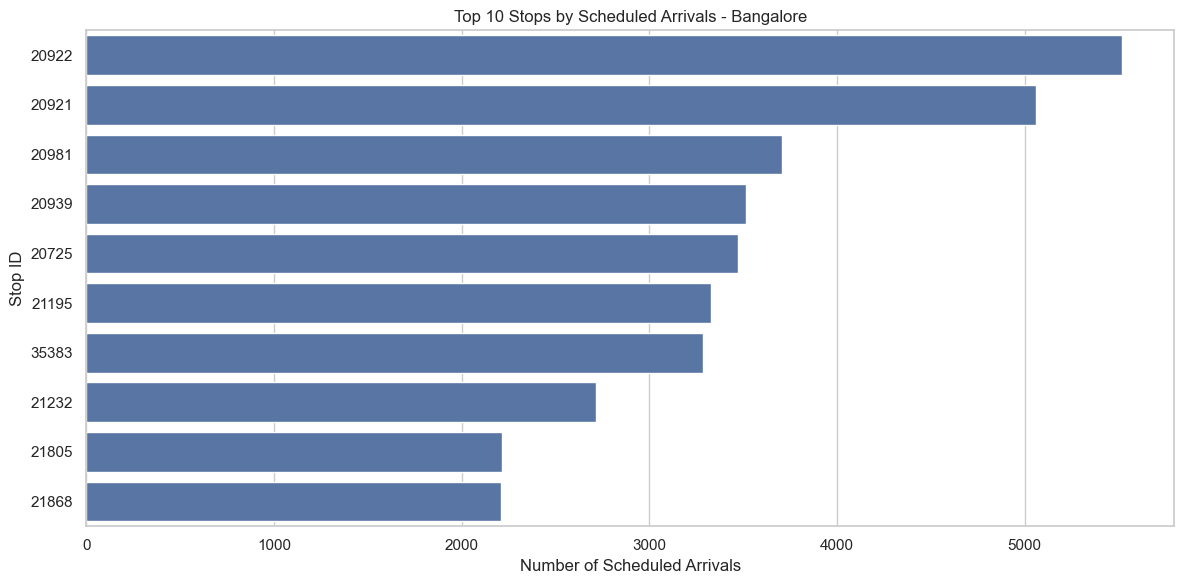

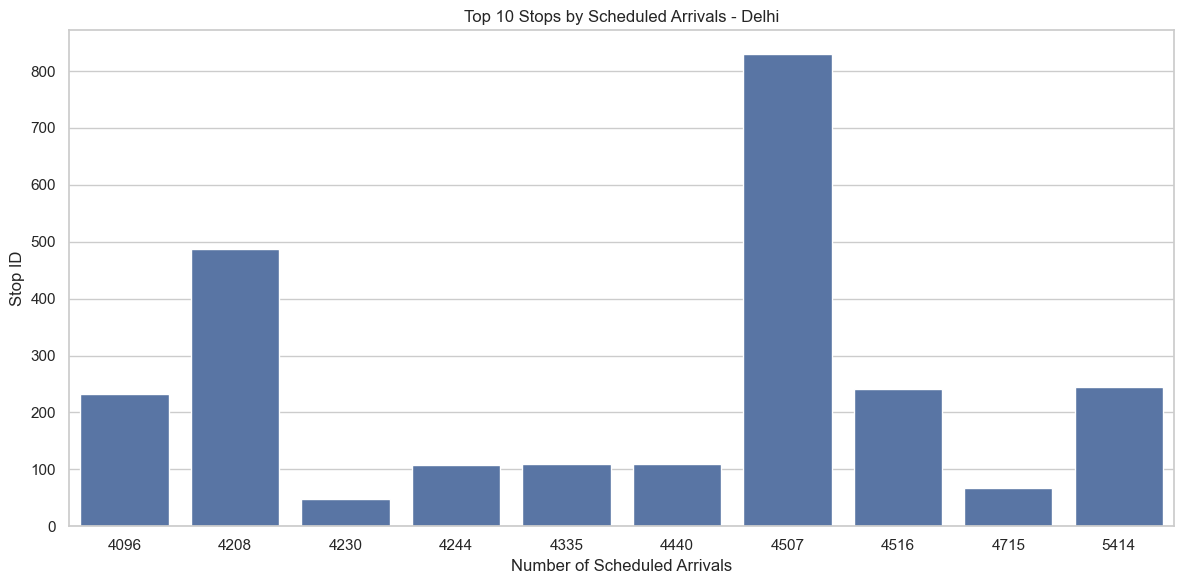

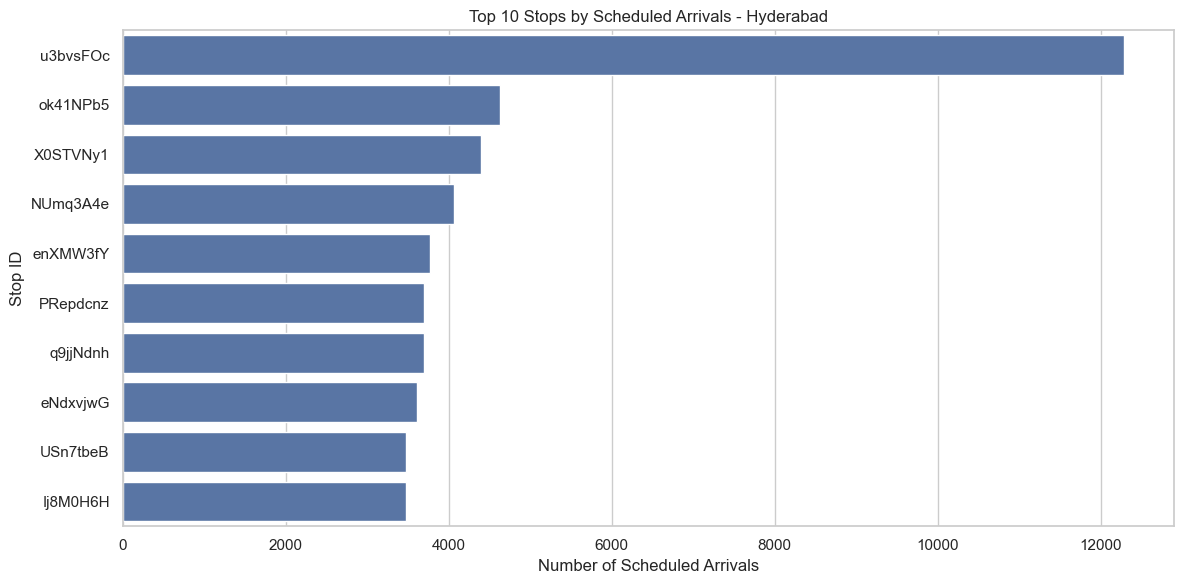

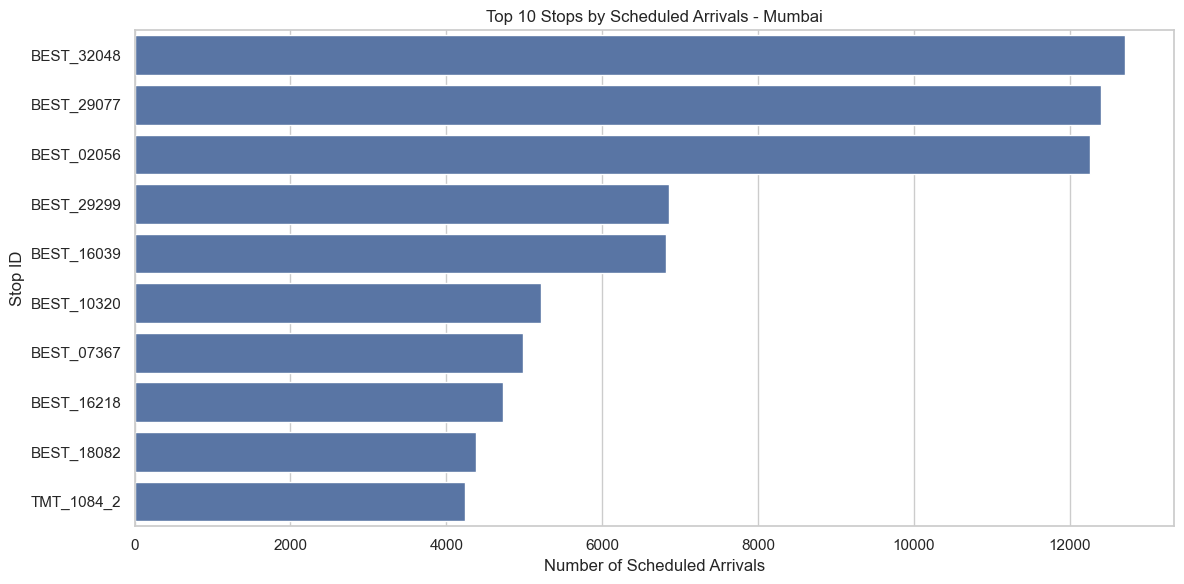

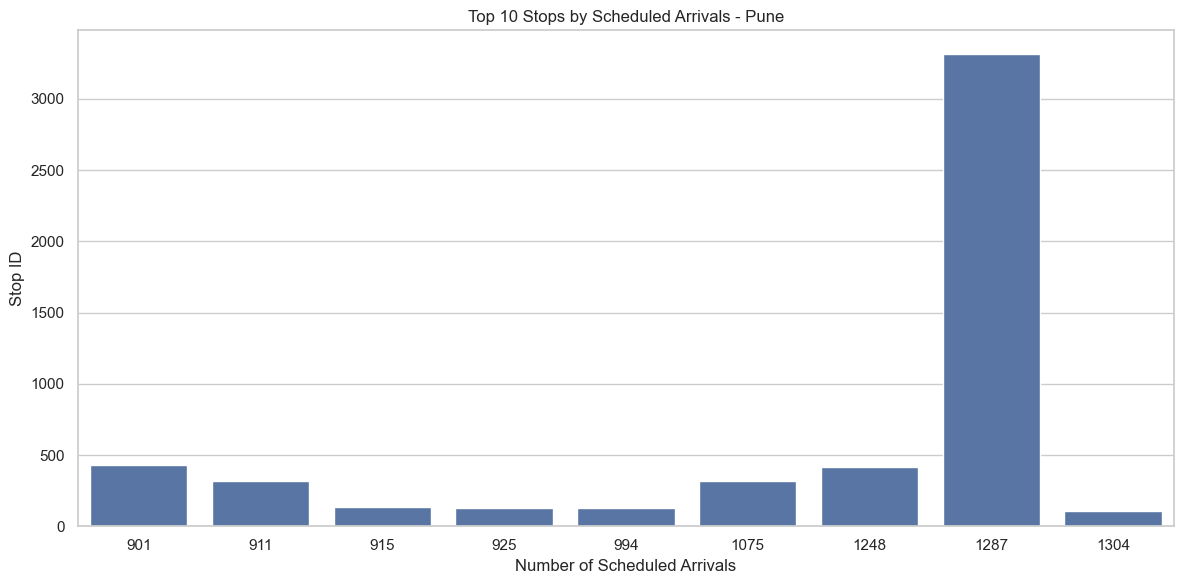

Top 10 stop charts saved successfully!


In [53]:
for city in top_stops["city"].unique():

    city_data = top_stops[top_stops["city"] == city]

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=city_data,
        x="scheduled_arrivals",
        y="stop_id"
    )

    plt.title(f"Top 10 Stops by Scheduled Arrivals - {city}")
    plt.xlabel("Number of Scheduled Arrivals")
    plt.ylabel("Stop ID")
    plt.tight_layout()

    plt.savefig(
        PROJECT / "visualizations" / "route_comparisons" /
        f"top_10_stops_{city.lower()}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("Top 10 stop charts saved successfully!")

In [54]:
top_stops.to_csv(
    PROJECT / "data" / "processed" / "module3" /
    "top_10_stops_by_city.csv",
    index=False
)

print("Top 10 stops CSV saved successfully!")

Top 10 stops CSV saved successfully!


In [55]:
hourly_arrival_summary = (
    arrival_df.groupby(["city", "arrival_clock_hour"])
    .size()
    .reset_index(name="arrival_count")
)

hourly_arrival_summary = hourly_arrival_summary.rename(
    columns={"arrival_clock_hour": "hour"}
)

display(hourly_arrival_summary.head(15))

,city,hour,arrival_count
0,Bangalore,0,472
1,Bangalore,1,1135
2,Bangalore,2,1186
3,Bangalore,3,1766
4,Bangalore,4,9685
5,Bangalore,5,44118
6,Bangalore,6,78255
7,Bangalore,7,94255
8,Bangalore,8,112327
9,Bangalore,9,113769


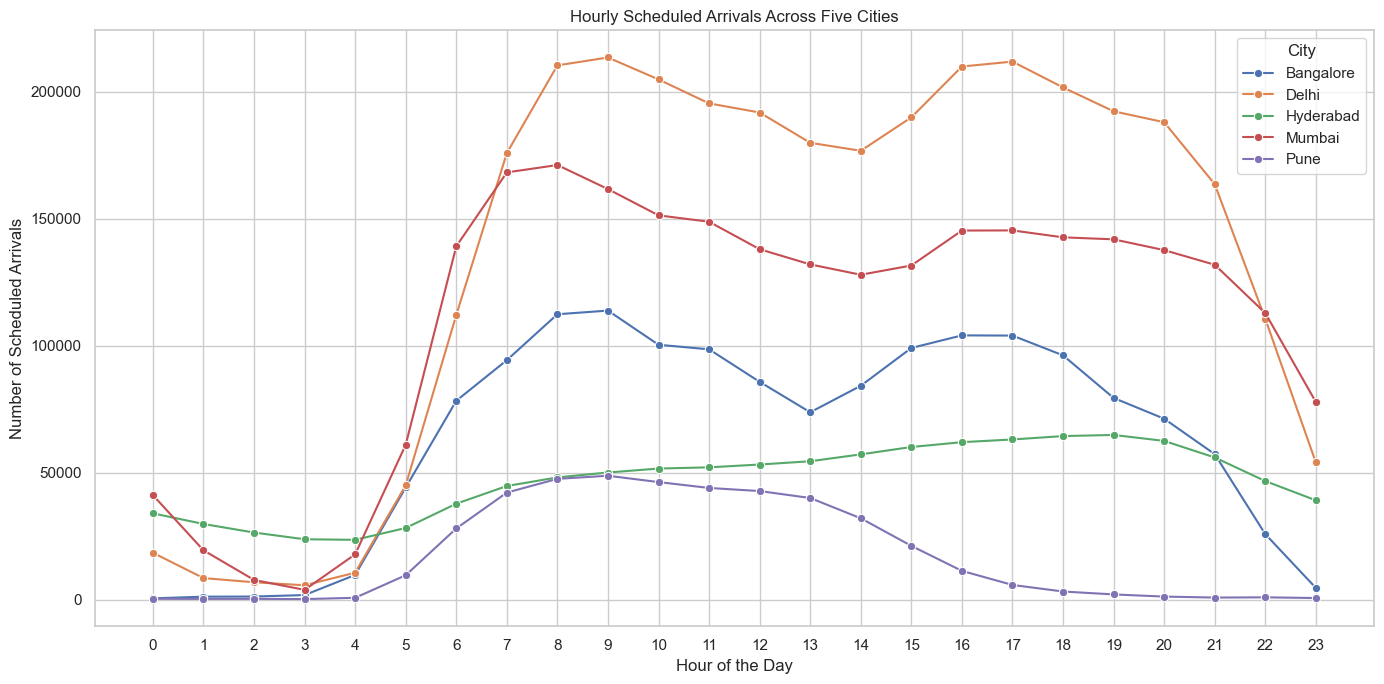

Hourly arrival chart saved successfully!


In [56]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=hourly_arrival_summary,
    x="hour",
    y="arrival_count",
    hue="city",
    marker="o"
)

plt.title("Hourly Scheduled Arrivals Across Five Cities")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Scheduled Arrivals")
plt.xticks(range(0, 24))
plt.grid(True)
plt.legend(title="City")
plt.tight_layout()

plt.savefig(
    PROJECT / "visualizations" / "hourly_patterns" /
    "hourly_arrival_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Hourly arrival chart saved successfully!")

In [57]:
hourly_arrival_summary.to_csv(
    PROJECT / "data" / "processed" / "module3" /
    "hourly_arrival_summary.csv",
    index=False
)

print("Hourly arrival summary CSV saved successfully!")

Hourly arrival summary CSV saved successfully!


In [58]:
stops_df = pd.read_csv(
    PROJECT / "data" / "raw" / "Banglore" / "stops.txt"
)

print("Dataset shape:", stops_df.shape)
print("\nAvailable columns:")
print(stops_df.columns.tolist())

display(stops_df.head())

Dataset shape: (9960, 9)

Available columns:
['stop_name', 'parent_station', 'zone_id', 'stop_id', 'stop_desc', 'stop_lat', 'stop_lon', 'location_type', 'platform_code']


,stop_name,parent_station,zone_id,stop_id,stop_desc,stop_lat,stop_lon,location_type,platform_code
0,12th Block Nagarabhavi,NaN,NBV12B,21629,12th Block Nagarabhavi (Towards AIT College),12.96018,77.51398,NaN,NaN
1,12th Block Nagarabhavi,NaN,NBV12B,21630,12th Block Nagarabhavi (Towards Nagarabhavi Ci...,12.96076,77.51351,NaN,NaN
2,14th Main HSR Layout,NaN,HSR14,20568,14th Main HSR Layout (Towards Hebbala),12.91637,77.63472,NaN,NaN
3,18th Main Jayanagara,NaN,JNR18,22890,18th Main Jayanagara (Towards Jayanagara 4th B...,12.92328,77.58898,NaN,NaN
4,19th Main 13th Cross HSR Layout,NaN,HSR13th,22891,19th Main 13th Cross HSR Layout (Towards Paran...,12.91593,77.65176,NaN,NaN


In [59]:
from pathlib import Path
import pandas as pd

cities = ["Banglore", "Delhi", "Hyderabad", "Mumbai", "Pune"]

all_stops = []

for city in cities:
    file_path = PROJECT / "data" / "raw" / city / "stops.txt"

    if file_path.exists():
        df = pd.read_csv(file_path)
        df["city"] = city
        all_stops.append(df)
        print(city, ":", len(df), "stops loaded")
    else:
        print(city, ": stops.txt file not found")

stops_all_df = pd.concat(all_stops, ignore_index=True)

print("\nCombined dataset shape:", stops_all_df.shape)
print("\nColumns:", stops_all_df.columns.tolist())

display(stops_all_df.head())

Banglore : 9960 stops loaded
Delhi : 6342 stops loaded
Hyderabad : 5028 stops loaded
Mumbai : 7506 stops loaded
Pune : 6745 stops loaded

Combined dataset shape: (35581, 11)

Columns: ['stop_name', 'parent_station', 'zone_id', 'stop_id', 'stop_desc', 'stop_lat', 'stop_lon', 'location_type', 'platform_code', 'city', 'stop_code']


,stop_name,parent_station,zone_id,stop_id,stop_desc,stop_lat,stop_lon,location_type,platform_code,city,stop_code
0,12th Block Nagarabhavi,NaN,NBV12B,21629,12th Block Nagarabhavi (Towards AIT College),12.96018,77.51398,NaN,NaN,Banglore,NaN
1,12th Block Nagarabhavi,NaN,NBV12B,21630,12th Block Nagarabhavi (Towards Nagarabhavi Ci...,12.96076,77.51351,NaN,NaN,Banglore,NaN
2,14th Main HSR Layout,NaN,HSR14,20568,14th Main HSR Layout (Towards Hebbala),12.91637,77.63472,NaN,NaN,Banglore,NaN
3,18th Main Jayanagara,NaN,JNR18,22890,18th Main Jayanagara (Towards Jayanagara 4th B...,12.92328,77.58898,NaN,NaN,Banglore,NaN
4,19th Main 13th Cross HSR Layout,NaN,HSR13th,22891,19th Main 13th Cross HSR Layout (Towards Paran...,12.91593,77.65176,NaN,NaN,Banglore,NaN


In [60]:
print("Missing latitude values:",
      stops_all_df["stop_lat"].isnull().sum())

print("Missing longitude values:",
      stops_all_df["stop_lon"].isnull().sum())

display(
    stops_all_df.groupby("city")
    .agg(
        total_stops=("stop_id", "count"),
        latitude_count=("stop_lat", "count"),
        longitude_count=("stop_lon", "count")
    )
)

Missing latitude values: 0
Missing longitude values: 0


,total_stops,latitude_count,longitude_count
city,,,
Banglore,9960,9960,9960
Delhi,6342,6342,6342
Hyderabad,5028,5028,5028
Mumbai,7506,7506,7506
Pune,6745,6745,6745


In [61]:
%pip install folium

  Using cached folium-0.20.0-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached branca-0.8.2-py3-none-any.whl.metadata (1.7 kB)
Using cached folium-0.20.0-py2.py3-none-any.whl (113 kB)
Using cached branca-0.8.2-py3-none-any.whl (26 kB)

   -------------------- ------------------- 1/2 [folium]
   -------------------- ------------------- 1/2 [folium]
   -------------------- ------------------- 1/2 [folium]
   ---------------------------------------- 2/2 [folium]

Note: you may need to restart the kernel to use updated packages.


In [62]:
import folium
from pathlib import Path

In [63]:
map_folder = PROJECT / "visualizations" / "geography"
map_folder.mkdir(parents=True, exist_ok=True)

for city in stops_all_df["city"].unique():

    city_stops = stops_all_df[
        (stops_all_df["city"] == city)
        & (stops_all_df["stop_lat"].notna())
        & (stops_all_df["stop_lon"].notna())
    ].copy()

    if city_stops.empty:
        print(city, "- No valid coordinates found")
        continue

    center_lat = city_stops["stop_lat"].mean()
    center_lon = city_stops["stop_lon"].mean()

    city_map = folium.Map(
        location=[center_lat, center_lon],
        zoom_start=11
    )

    for _, stop in city_stops.iterrows():
        folium.CircleMarker(
            location=[stop["stop_lat"], stop["stop_lon"]],
            radius=2,
            popup=str(stop["stop_name"]),
            fill=True
        ).add_to(city_map)

    filename = f"{city.lower()}_stop_map.html"

    city_map.save(map_folder / filename)

    print(city, "map saved:", filename)

Banglore map saved: banglore_stop_map.html
Delhi map saved: delhi_stop_map.html
Hyderabad map saved: hyderabad_stop_map.html
Mumbai map saved: mumbai_stop_map.html
Pune map saved: pune_stop_map.html


In [65]:
for city in stops_all_df["city"].unique():

    city_stops = stops_all_df[
        stops_all_df["city"] == city
    ].copy()

    print("\nCity:", city)
    print("Total stops:", len(city_stops))
    print("Valid latitude:",
          city_stops["stop_lat"].notna().sum())
    print("Valid longitude:",
          city_stops["stop_lon"].notna().sum())

    print(city_stops[["stop_lat", "stop_lon"]].head())


City: Banglore
Total stops: 9960
Valid latitude: 9960
Valid longitude: 9960
   stop_lat  stop_lon
0  12.96018  77.51398
1  12.96076  77.51351
2  12.91637  77.63472
3  12.92328  77.58898
4  12.91593  77.65176

City: Delhi
Total stops: 6342
Valid latitude: 6342
Valid longitude: 6342
       stop_lat   stop_lon
9960  28.852004  77.088059
9961  28.853366  77.088535
9962  28.855266  77.089730
9963  28.857752  77.092856
9964  28.857652  77.095746

City: Hyderabad
Total stops: 5028
Valid latitude: 5028
Valid longitude: 5028
        stop_lat   stop_lon
16302  17.358678  78.474028
16303  17.354750  78.473024
16304  17.360127  78.471375
16305  17.364275  78.466668
16306  17.367453  78.468290

City: Mumbai
Total stops: 7506
Valid latitude: 7506
Valid longitude: 7506
       stop_lat  stop_lon
21330  19.23673  73.13028
21331  19.24361  73.13043
21332  19.24227  73.13659
21333  19.24226  73.13976
21334  19.24214  73.13972

City: Pune
Total stops: 6745
Valid latitude: 6745
Valid longitude: 6745
     

In [66]:
display(
    stops_all_df[
        ["city", "stop_name", "stop_lat", "stop_lon"]
    ].head(10)
)

,city,stop_name,stop_lat,stop_lon
0,Banglore,12th Block Nagarabhavi,12.96018,77.51398
1,Banglore,12th Block Nagarabhavi,12.96076,77.51351
2,Banglore,14th Main HSR Layout,12.91637,77.63472
3,Banglore,18th Main Jayanagara,12.92328,77.58898
4,Banglore,19th Main 13th Cross HSR Layout,12.91593,77.65176
5,Banglore,19th Main 13th Cross HSR Layout,12.91582,77.65175
6,Banglore,1st Main Kodichikkanahalli,12.89854,77.61543
7,Banglore,1st Main Kodichikkanahalli,12.89847,77.61550
8,Banglore,1st Stage 3rd Block Nagarabhavi (Nayandahalli),12.95302,77.52026
9,Banglore,1st Stage 3rd Block Nagarabhavi (Summanahalli),12.95286,77.52017


In [68]:
test_html = test_map.get_root().render()

print("HTML length:", len(test_html))
print("Contains Leaflet:", "leaflet" in test_html.lower())
print("Contains Hyderabad marker:", "Hyderabad Test Stop" in test_html)
print(test_html[:500])

HTML length: 4194
Contains Leaflet: True
Contains Hyderabad marker: True
<!DOCTYPE html>
<html>
<head>
    
    <meta http-equiv="content-type" content="text/html; charset=UTF-8" />
    <script src="https://cdn.jsdelivr.net/npm/leaflet@1.9.3/dist/leaflet.js"></script>
    <script src="https://code.jquery.com/jquery-3.7.1.min.js"></script>
    <script src="https://cdn.jsdelivr.net/npm/bootstrap@5.2.2/dist/js/bootstrap.bundle.min.js"></script>
    <script src="https://cdnjs.cloudflare.com/ajax/libs/Leaflet.awesome-markers/2.0.2/leaflet.awesome-markers.js"></script>
   


In [69]:
import folium
import IPython

print("Folium version:", folium.__version__)
print("IPython version:", IPython.__version__)

Folium version: 0.20.0
IPython version: 8.30.0


In [70]:
%pip install --upgrade folium branca

In [1]:
print("Jupyter Notebook is working!")

Jupyter Notebook is working!


In [1]:
print("Hello! Jupyter is working.")

Hello! Jupyter is working.


In [2]:
print("Module 3 EDA is working!")

Module 3 EDA is working!


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [5]:
PROJECT = Path.cwd().parent

MODULE2 = PROJECT / "data" / "processed" / "module2"

print("Project path:", PROJECT)
print("Module 2 path:", MODULE2)

Project path: c:\Users\nagar\Downloads\routeranker-upload
Module 2 path: c:\Users\nagar\Downloads\routeranker-upload\data\processed\module2


In [6]:
route_df = pd.read_csv(
    MODULE2 / "all_cities_route_profile.csv"
)

print("Route dataset loaded successfully!")
print("Shape:", route_df.shape)

display(route_df.head())

Route dataset loaded successfully!
Shape: (9679, 10)


,route_long_name,route_short_name,agency_id,route_type,route_id,trip_count,service_count,distinct_stop_count,average_stops_per_trip,city
0,2nd Stage 9th Block Nagarabhavi ⇔ Shivajinagar...,244-C VSD,1,3,3447,2.0,1.0,41.0,21.500000,Bangalore
1,5th Block HBR Layout ⇔ Kalyananagara Bus Stand,KLN-HBR,1,3,7041,2.0,1.0,7.0,4.500000,Bangalore
2,5th Block HBR Layout ⇔ Kempegowda Bus Station,296,1,3,2712,3.0,1.0,44.0,22.333333,Bangalore
3,5th Block HBR Layout ⇔ Kempegowda Bus Station,296-B,1,3,4821,4.0,1.0,44.0,22.500000,Bangalore
4,5th Block HBR Layout ⇔ Shivajinagara Bus Station,296-D,1,3,2809,3.0,1.0,38.0,19.000000,Bangalore


In [7]:
correlation_df = route_df[
    [
        "trip_count",
        "service_count",
        "distinct_stop_count",
        "average_stops_per_trip"
    ]
].copy()

correlation_matrix = correlation_df.corr()

display(correlation_matrix.round(2))

,trip_count,service_count,distinct_stop_count,average_stops_per_trip
trip_count,1.00,NaN,0.22,-0.05
service_count,NaN,NaN,NaN,NaN
distinct_stop_count,0.22,NaN,1.00,0.67
average_stops_per_trip,-0.05,NaN,0.67,1.00


In [8]:
city_correlations = {}

features = [
    "trip_count",
    "service_count",
    "distinct_stop_count",
    "average_stops_per_trip"
]

for city in route_df["city"].unique():

    city_data = route_df[
        route_df["city"] == city
    ][features]

    city_correlations[city] = city_data.corr()

    print("\nCorrelation for:", city)
    display(city_correlations[city].round(2))


Correlation for: Bangalore


,trip_count,service_count,distinct_stop_count,average_stops_per_trip
trip_count,1.00,NaN,0.03,-0.05
service_count,NaN,NaN,NaN,NaN
distinct_stop_count,0.03,NaN,1.00,0.90
average_stops_per_trip,-0.05,NaN,0.90,1.00



Correlation for: Delhi


,trip_count,service_count,distinct_stop_count,average_stops_per_trip
trip_count,1.00,NaN,0.09,0.09
service_count,NaN,NaN,NaN,NaN
distinct_stop_count,0.09,NaN,1.00,1.00
average_stops_per_trip,0.09,NaN,1.00,1.00



Correlation for: Hyderabad


,trip_count,service_count,distinct_stop_count,average_stops_per_trip
trip_count,1.00,NaN,0.70,-0.01
service_count,NaN,NaN,NaN,NaN
distinct_stop_count,0.70,NaN,1.00,0.34
average_stops_per_trip,-0.01,NaN,0.34,1.00



Correlation for: Mumbai


,trip_count,service_count,distinct_stop_count,average_stops_per_trip
trip_count,1.00,NaN,-0.09,-0.18
service_count,NaN,NaN,NaN,NaN
distinct_stop_count,-0.09,NaN,1.00,0.93
average_stops_per_trip,-0.18,NaN,0.93,1.00



Correlation for: Pune


,trip_count,service_count,distinct_stop_count,average_stops_per_trip
trip_count,1.00,NaN,-0.13,-0.15
service_count,NaN,NaN,NaN,NaN
distinct_stop_count,-0.13,NaN,1.00,0.98
average_stops_per_trip,-0.15,NaN,0.98,1.00


In [9]:
correlation_results = []

for city, matrix in city_correlations.items():

    for feature1 in matrix.columns:
        for feature2 in matrix.columns:

            correlation_results.append({
                "city": city,
                "feature_1": feature1,
                "feature_2": feature2,
                "correlation": matrix.loc[feature1, feature2]
            })

city_correlation_df = pd.DataFrame(correlation_results)

city_correlation_df.to_csv(
    PROJECT / "data" / "processed" / "module3" /
    "city_wise_correlations.csv",
    index=False
)

print("City-wise correlation CSV saved successfully!")

City-wise correlation CSV saved successfully!


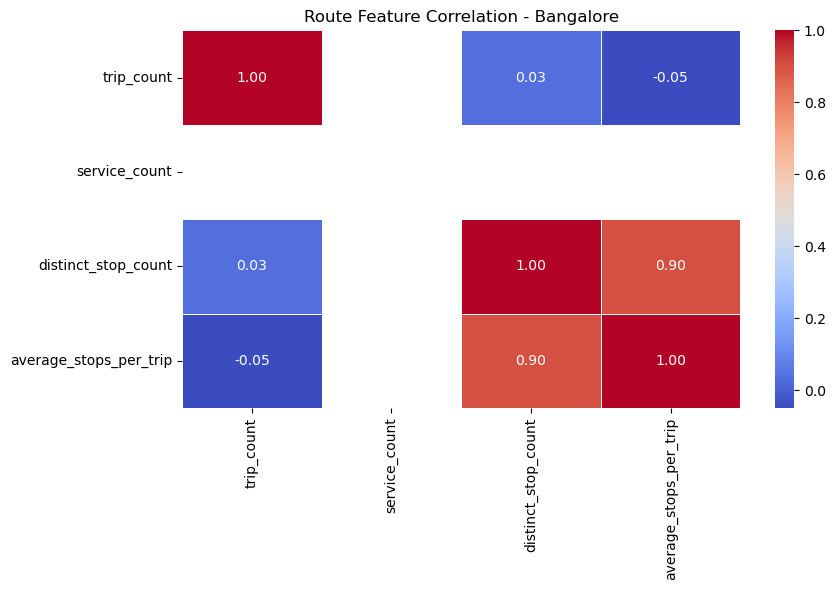

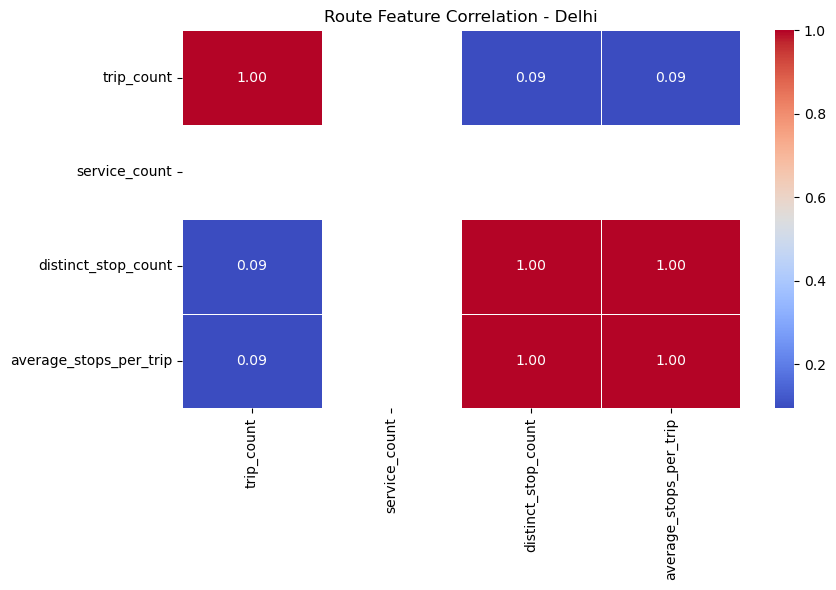

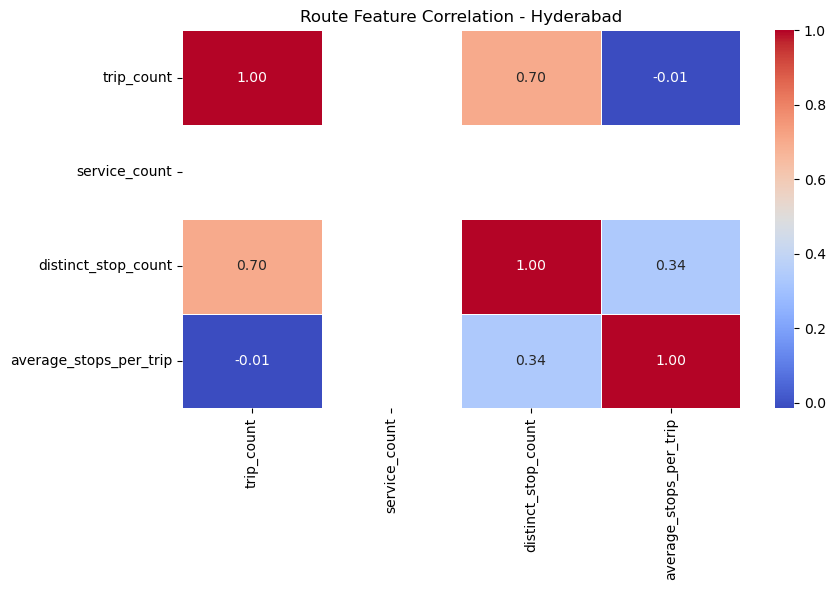

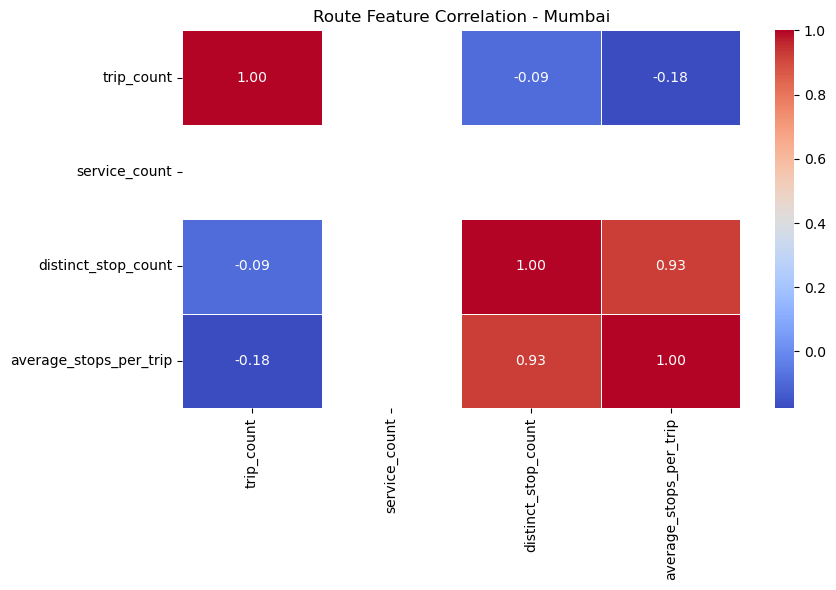

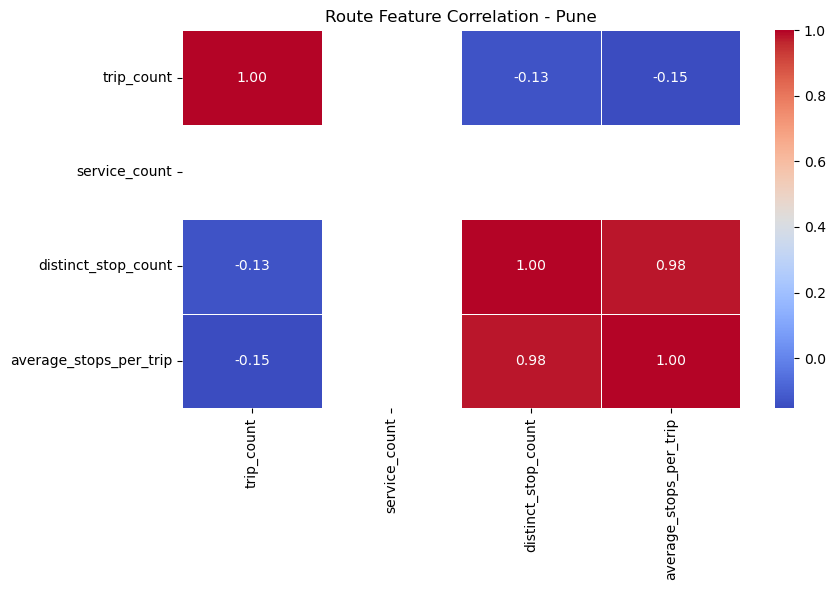

All five city correlation heatmaps saved!


In [10]:
for city, matrix in city_correlations.items():

    plt.figure(figsize=(9, 6))

    sns.heatmap(
        matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )

    plt.title(f"Route Feature Correlation - {city}")
    plt.tight_layout()

    plt.savefig(
        PROJECT / "visualizations" / "correlations" /
        f"correlation_{city.lower()}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("All five city correlation heatmaps saved!")

In [11]:
eda_summary = (
    route_df.groupby("city")
    .agg(
        total_routes=("route_id", "nunique"),
        total_scheduled_trips=("trip_count", "sum"),
        average_trips_per_route=("trip_count", "mean"),
        average_stops_per_route=("distinct_stop_count", "mean")
    )
    .reset_index()
)

display(eda_summary.round(2))

,city,total_routes,total_scheduled_trips,average_trips_per_route,average_stops_per_route
0,Bangalore,4434,57836.0,13.10,47.59
1,Delhi,2964,78507.0,26.49,39.80
2,Hyderabad,1031,44892.0,43.54,63.86
3,Mumbai,935,99080.0,161.90,48.26
4,Pune,315,10128.0,32.15,82.09


In [12]:
eda_summary.to_csv(
    PROJECT / "data" / "processed" / "module3" /
    "final_eda_summary.csv",
    index=False
)

print("Final EDA summary saved successfully!")

Final EDA summary saved successfully!


In [13]:
report_folder = PROJECT / "reports" / "module3"
report_folder.mkdir(parents=True, exist_ok=True)

print("Module 3 report folder created!")

Module 3 report folder created!


In [14]:
report_text = f"""
ROUTERANKER – AI-POWERED PUBLIC TRANSIT ROUTE OPTIMIZATION

MODULE 3: EXPLORATORY DATA ANALYSIS (EDA)

1. OBJECTIVE
To explore and understand GTFS public transit datasets
from five Indian cities.

2. CITIES ANALYZED
Bangalore, Delhi, Hyderabad, Mumbai and Pune.

3. ANALYSIS PERFORMED
- Distribution of scheduled trips per route
- Hourly scheduled service patterns
- Time-period departure analysis
- Route-wise scheduled headway analysis
- Route-wise hourly service analysis
- Top 10 scheduled routes by city
- Top 10 stops by scheduled arrivals
- Geographic distribution of bus stops
- Correlation between route features

4. KEY DATASET
Total route records: {len(route_df)}

5. CITY-WISE SUMMARY

{eda_summary.round(2).to_string(index=False)}

6. CONCLUSION
EDA helped identify differences in scheduled service
patterns, route characteristics, headways and stop
distribution across the five cities.

These findings can support subsequent data preprocessing,
feature selection and route optimization.

Note: GTFS schedules represent planned service, not actual
passenger demand or real-time vehicle operations.
"""

report_path = report_folder / "Module3_EDA_Report.txt"

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report_text)

print("Module 3 EDA report saved:", report_path)

Module 3 EDA report saved: c:\Users\nagar\Downloads\routeranker-upload\reports\module3\Module3_EDA_Report.txt


In [15]:
module3_folder = PROJECT / "data" / "processed" / "module3"

print("MODULE 3 PROCESSED FILES\n")

for file in sorted(module3_folder.glob("*")):
    if file.is_file():
        print(f"✓ {file.name} | {file.stat().st_size / 1024:.2f} KB")

MODULE 3 PROCESSED FILES

✓ city_route_summary.csv | 0.36 KB
✓ city_wise_correlations.csv | 4.02 KB
✓ final_eda_summary.csv | 0.37 KB
✓ hourly_arrival_summary.csv | 2.04 KB
✓ route_hourly_summary.csv | 1.85 KB
✓ top_10_routes_by_city.csv | 4.15 KB
✓ top_10_stops_by_city.csv | 1.03 KB


In [16]:
visualization_folder = PROJECT / "visualizations"

print("MODULE 3 VISUALIZATION FILES\n")

for folder in visualization_folder.iterdir():
    if folder.is_dir():
        files = list(folder.glob("*"))
        print(f"\n{folder.name}: {len(files)} files")

        for file in files:
            print("  ✓", file.name)

MODULE 3 VISUALIZATION FILES


correlations: 5 files
  ✓ correlation_bangalore.png
  ✓ correlation_delhi.png
  ✓ correlation_hyderabad.png
  ✓ correlation_mumbai.png
  ✓ correlation_pune.png

distributions: 2 files
  ✓ trip_count_distribution.png
  ✓ trip_distribution_by_city.png

geography: 5 files
  ✓ banglore_stop_map.html
  ✓ delhi_stop_map.html
  ✓ hyderabad_stop_map.html
  ✓ mumbai_stop_map.html
  ✓ pune_stop_map.html

hourly_patterns: 4 files
  ✓ hourly_arrival_comparison.png
  ✓ hourly_trips_all_cities.png
  ✓ route_wise_hourly_comparison.png
  ✓ time_period_comparison.png

route_comparisons: 12 files
  ✓ headway_comparison.png
  ✓ route_trip_comparison.png
  ✓ top_10_routes_bangalore.png
  ✓ top_10_routes_delhi.png
  ✓ top_10_routes_hyderabad.png
  ✓ top_10_routes_mumbai.png
  ✓ top_10_routes_pune.png
  ✓ top_10_stops_bangalore.png
  ✓ top_10_stops_delhi.png
  ✓ top_10_stops_hyderabad.png
  ✓ top_10_stops_mumbai.png
  ✓ top_10_stops_pune.png


In [17]:
report_folder = PROJECT / "reports" / "module3"

print("REPORT FILES\n")

for file in report_folder.glob("*"):
    print("✓", file.name)

REPORT FILES

✓ Module3_EDA_Report.txt


In [18]:
from pathlib import Path
import pandas as pd

module3_folder = PROJECT / "data" / "processed" / "module3"

print("MODULE 3 CSV FILE VERIFICATION")
print("=" * 50)

csv_files = sorted(module3_folder.glob("*.csv"))

for file in csv_files:
    try:
        df = pd.read_csv(file)

        print(f"\nFile: {file.name}")
        print("Status: SUCCESS")
        print("Rows:", len(df))
        print("Columns:", len(df.columns))
        print("Column names:", df.columns.tolist())

    except Exception as e:
        print(f"\nFile: {file.name}")
        print("Status: ERROR")
        print(e)

print("\nTotal CSV files:", len(csv_files))

MODULE 3 CSV FILE VERIFICATION

File: city_route_summary.csv
Status: SUCCESS
Rows: 5
Columns: 6
Column names: ['city', 'route_count', 'total_scheduled_trips', 'average_trips_per_route', 'median_trips_per_route', 'maximum_trips_on_a_route']

File: city_wise_correlations.csv
Status: SUCCESS
Rows: 80
Columns: 4
Column names: ['city', 'feature_1', 'feature_2', 'correlation']

File: final_eda_summary.csv
Status: SUCCESS
Rows: 5
Columns: 5
Column names: ['city', 'total_routes', 'total_scheduled_trips', 'average_trips_per_route', 'average_stops_per_route']

File: hourly_arrival_summary.csv
Status: SUCCESS
Rows: 120
Columns: 3
Column names: ['city', 'hour', 'arrival_count']

File: route_hourly_summary.csv
Status: SUCCESS
Rows: 120
Columns: 3
Column names: ['city', 'hour', 'trip_count']

File: top_10_routes_by_city.csv
Status: SUCCESS
Rows: 50
Columns: 10
Column names: ['route_long_name', 'route_short_name', 'agency_id', 'route_type', 'route_id', 'trip_count', 'service_count', 'distinct_stop_co

In [19]:
required_csv_files = [
    "city_route_summary.csv",
    "route_hourly_summary.csv",
    "top_10_routes_by_city.csv",
    "top_10_stops_by_city.csv",
    "hourly_arrival_summary.csv",
    "route_feature_correlation.csv",
    "city_wise_correlations.csv",
    "final_eda_summary.csv"
]

print("REQUIRED CSV CHECK")
print("=" * 40)

for filename in required_csv_files:
    file_path = module3_folder / filename

    if file_path.exists() and file_path.stat().st_size > 0:
        print("SUCCESS:", filename)
    else:
        print("MISSING OR EMPTY:", filename)

REQUIRED CSV CHECK
SUCCESS: city_route_summary.csv
SUCCESS: route_hourly_summary.csv
SUCCESS: top_10_routes_by_city.csv
SUCCESS: top_10_stops_by_city.csv
SUCCESS: hourly_arrival_summary.csv
MISSING OR EMPTY: route_feature_correlation.csv
SUCCESS: city_wise_correlations.csv
SUCCESS: final_eda_summary.csv


In [20]:
map_folder = PROJECT / "visualizations" / "geography"

required_maps = [
    "banglore_stop_map.html",
    "delhi_stop_map.html",
    "hyderabad_stop_map.html",
    "mumbai_stop_map.html",
    "pune_stop_map.html"
]

print("GEOGRAPHIC MAP FILE CHECK")
print("=" * 40)

for filename in required_maps:
    file_path = map_folder / filename

    if file_path.exists():
        content = file_path.read_text(
            encoding="utf-8",
            errors="ignore"
        )

        has_map = "leaflet" in content.lower()
        has_coordinates = "center" in content.lower()

        print(
            filename,
            "| File exists:",
            True,
            "| Leaflet:",
            has_map,
            "| Map center:",
            has_coordinates,
            "| Size:",
            round(file_path.stat().st_size / 1024, 2),
            "KB"
        )
    else:
        print(filename, "| MISSING")

GEOGRAPHIC MAP FILE CHECK
banglore_stop_map.html | File exists: True | Leaflet: True | Map center: True | Size: 10057.98 KB
delhi_stop_map.html | File exists: True | Leaflet: True | Map center: True | Size: 6436.45 KB
hyderabad_stop_map.html | File exists: True | Leaflet: True | Map center: True | Size: 5138.7 KB
mumbai_stop_map.html | File exists: True | Leaflet: True | Map center: True | Size: 7618.71 KB
pune_stop_map.html | File exists: True | Leaflet: True | Map center: True | Size: 6851.91 KB


In [21]:
import pandas as pd
from pathlib import Path

# Load the Module 2 route profile
module2_folder = PROJECT / "data" / "processed" / "module2"

route_df = pd.read_csv(
    module2_folder / "all_cities_route_profile.csv"
)

# Select numerical features
features = [
    "trip_count",
    "service_count",
    "distinct_stop_count",
    "average_stops_per_trip"
]

# Calculate correlation
correlation_matrix = route_df[features].corr()

# Display the result
print("ROUTE FEATURE CORRELATION")
display(correlation_matrix.round(3))

# Save CSV
output_file = module3_folder / "route_feature_correlation.csv"
correlation_matrix.to_csv(output_file)

print("\nSUCCESS: Saved", output_file)

ROUTE FEATURE CORRELATION


,trip_count,service_count,distinct_stop_count,average_stops_per_trip
trip_count,1.000,NaN,0.216,-0.049
service_count,NaN,NaN,NaN,NaN
distinct_stop_count,0.216,NaN,1.000,0.669
average_stops_per_trip,-0.049,NaN,0.669,1.000



SUCCESS: Saved c:\Users\nagar\Downloads\routeranker-upload\data\processed\module3\route_feature_correlation.csv


In [22]:
check_df = pd.read_csv(
    module3_folder / "route_feature_correlation.csv"
)

print("File exists:", (module3_folder / "route_feature_correlation.csv").exists())
print("Rows:", len(check_df))
print("Columns:", list(check_df.columns))
display(check_df)

File exists: True
Rows: 4
Columns: ['Unnamed: 0', 'trip_count', 'service_count', 'distinct_stop_count', 'average_stops_per_trip']


,Unnamed: 0,trip_count,service_count,distinct_stop_count,average_stops_per_trip
0,trip_count,1.000000,NaN,0.216443,-0.049197
1,service_count,NaN,NaN,NaN,NaN
2,distinct_stop_count,0.216443,NaN,1.000000,0.668693
3,average_stops_per_trip,-0.049197,NaN,0.668693,1.000000


In [23]:
map_folder = PROJECT / "visualizations" / "geography"

required_maps = [
    "banglore_stop_map.html",
    "delhi_stop_map.html",
    "hyderabad_stop_map.html",
    "mumbai_stop_map.html",
    "pune_stop_map.html"
]

print("GEOGRAPHIC MAP FILE VERIFICATION")
print("=" * 50)

for filename in required_maps:
    file_path = map_folder / filename

    if file_path.exists():
        print(f"SUCCESS: {filename} | Size: {file_path.stat().st_size:,} bytes")
    else:
        print(f"MISSING: {filename}")

GEOGRAPHIC MAP FILE VERIFICATION
SUCCESS: banglore_stop_map.html | Size: 10,299,372 bytes
SUCCESS: delhi_stop_map.html | Size: 6,590,924 bytes
SUCCESS: hyderabad_stop_map.html | Size: 5,262,027 bytes
SUCCESS: mumbai_stop_map.html | Size: 7,801,558 bytes
SUCCESS: pune_stop_map.html | Size: 7,016,357 bytes


In [24]:
for filename in required_maps:
    file_path = map_folder / filename

    if file_path.exists():
        html = file_path.read_text(encoding="utf-8")

        print("\n", filename)
        print("HTML size:", len(html))
        print("Contains Leaflet:", "leaflet" in html.lower())
        print("Contains map container:", "folium-map" in html.lower())


 banglore_stop_map.html
HTML size: 10299358
Contains Leaflet: True
Contains map container: True

 delhi_stop_map.html
HTML size: 6590924
Contains Leaflet: True
Contains map container: True

 hyderabad_stop_map.html
HTML size: 5262027
Contains Leaflet: True
Contains map container: True

 mumbai_stop_map.html
HTML size: 7801558
Contains Leaflet: True
Contains map container: True

 pune_stop_map.html
HTML size: 7016357
Contains Leaflet: True
Contains map container: True


In [25]:
for filename in required_maps:
    file_path = map_folder / filename

    if file_path.exists():
        html = file_path.read_text(encoding="utf-8")

        print("\n", filename)
        print("HTML size:", len(html))
        print("Contains Leaflet:", "leaflet" in html.lower())
        print("Contains map container:", "folium-map" in html.lower())


 banglore_stop_map.html
HTML size: 10299358
Contains Leaflet: True
Contains map container: True

 delhi_stop_map.html
HTML size: 6590924
Contains Leaflet: True
Contains map container: True

 hyderabad_stop_map.html
HTML size: 5262027
Contains Leaflet: True
Contains map container: True

 mumbai_stop_map.html
HTML size: 7801558
Contains Leaflet: True
Contains map container: True

 pune_stop_map.html
HTML size: 7016357
Contains Leaflet: True
Contains map container: True


In [27]:
import webbrowser

map_file = map_folder / "hyderabad_stop_map.html"

webbrowser.open(map_file.resolve().as_uri())

True

In [29]:
print("Hello! Jupyter Notebook is working.")
print(10 + 20)

Hello! Jupyter Notebook is working.
30


In [1]:
print("Jupyter is working")

Jupyter is working
